In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.contingency_tables import mcnemar

In [2]:
model1_results = pd.read_csv("../Model1/model1_results.csv")
model2_results = pd.read_csv("../Model2/model2_results.csv")

print("Model 1 results:")
display(model1_results)

print("\nModel 2 results:")
display(model2_results)

Model 1 results:


,Metric,Logistic Regression
0,Accuracy,0.845848
1,Precision,0.418129
2,Recall,0.810964
3,F1-score,0.551768
4,ROC-AUC,0.909661



Model 2 results:


,Metric,Random Forest
0,Accuracy,0.896605
1,Precision,0.552340
2,Recall,0.613422
3,F1-score,0.581281
4,ROC-AUC,0.926581


In [3]:
comparison = pd.merge(
    model1_results,
    model2_results,
    on="Metric",
    how="inner"
)

comparison

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.845848,0.896605
1,Precision,0.418129,0.552340
2,Recall,0.810964,0.613422
3,F1-score,0.551768,0.581281
4,ROC-AUC,0.909661,0.926581


In [4]:
comparison_rounded = comparison.copy()

numeric_columns = comparison_rounded.select_dtypes(
    include=["float64", "int64"]
).columns

comparison_rounded[numeric_columns] = (
    comparison_rounded[numeric_columns].round(4)
)

comparison_rounded

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8458,0.8966
1,Precision,0.4181,0.5523
2,Recall,0.8110,0.6134
3,F1-score,0.5518,0.5813
4,ROC-AUC,0.9097,0.9266


In [5]:
comparison_rounded.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully.")

Model comparison results saved successfully.


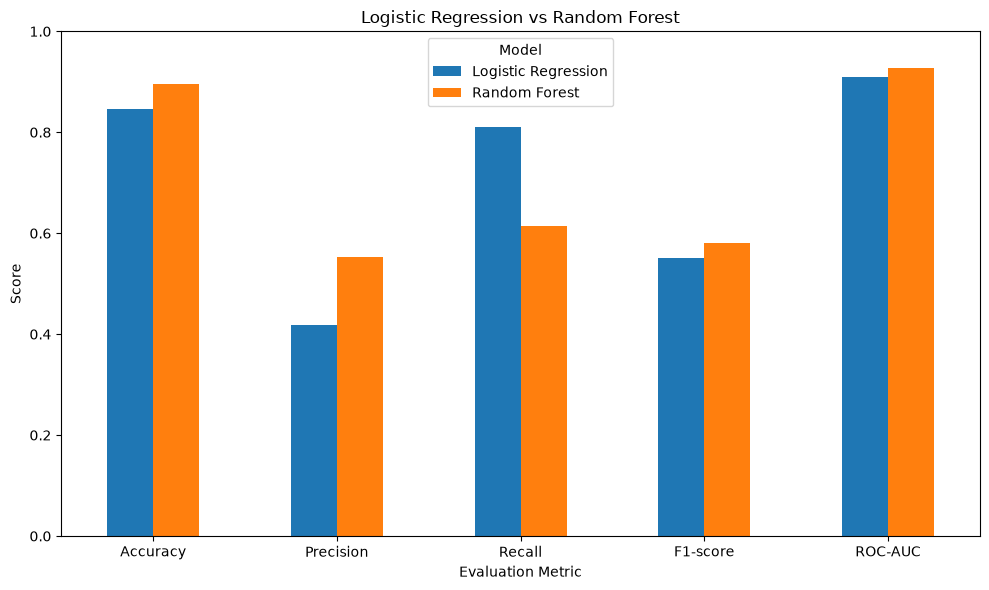

In [6]:
plot_data = comparison.set_index("Metric")

plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

In [7]:
model_columns = [
    column
    for column in comparison.columns
    if column != "Metric"
]

for _, row in comparison.iterrows():

    metric = row["Metric"]

    scores = {
        model: row[model]
        for model in model_columns
    }

    highest_model = max(
        scores,
        key=scores.get
    )

    print(
        f"{metric}: "
        f"{highest_model} has the higher value "
        f"({scores[highest_model]:.4f})"
    )

Accuracy: Random Forest has the higher value (0.8966)
Precision: Random Forest has the higher value (0.5523)
Recall: Logistic Regression has the higher value (0.8110)
F1-score: Random Forest has the higher value (0.5813)
ROC-AUC: Random Forest has the higher value (0.9266)


In [8]:
comparison_percent = comparison.copy()

for column in model_columns:
    comparison_percent[column] = (
        comparison_percent[column] * 100
    ).round(2)

comparison_percent

,Metric,Logistic Regression,Random Forest
0,Accuracy,84.58,89.66
1,Precision,41.81,55.23
2,Recall,81.10,61.34
3,F1-score,55.18,58.13
4,ROC-AUC,90.97,92.66
